# 🧪 LAB: Implement an autoencoder with `PyTorch`

In this lab, you will implement and explore autoencoders using the MNIST dataset. The goal is to understand how autoencoders learn compressed representations of data, and how these representations compare with classical methods like PCA.

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = ""

## 1. Theoretical Background Reflection (10 points)

Read *Michelucci (2022)*: [An Introduction to Autoencoders](https://arxiv.org/abs/2201.03898) — focus on the following sections:  
- 1. Introduction
- 2.1, 2.2, and 2.3
- Skim Section 3 on applications  

Then answer briefly:

1. What is the main idea behind an autoencoder?  
2. What is the role of the bottleneck layer?  
3. Discuss, in your own words, the applications of autoencoders mentioned in the paper.  
4. What differences would you expect between an autoencoder’s representation and that of PCA if applied as a dimensionality reduction technique?


**1. Main idea.** An autoencoder is a neural network trained to reproduce its own input. It has two parts. The *encoder* $g$ maps an input $x$ to a lower-dimensional code $h = g(x)$, and the *decoder* $f$ maps that code back to a reconstruction $\tilde{x} = f(g(x))$. Both are trained together to minimize a reconstruction loss $\mathcal{L}(x, \tilde{x})$. No labels are needed (it is unsupervised, or self-supervised). The goal is not the copy itself but the code $h$: to reconstruct well from a small code, the network has to learn the structure that actually matters in the data.

**2. Role of the bottleneck.** The bottleneck is the narrowest layer, here 2 units. It does two things:
- **It forces compression.** All the information the decoder gets has to pass through those few numbers, so the encoder must keep the most informative factors of variation and drop the rest.
- **It blocks the trivial solution.** If the code were as wide as the input, the network could learn the identity map and reconstruct perfectly while learning nothing useful. The bottleneck (or another constraint, such as sparsity or noise) prevents that, and its output is the learned low-dimensional representation.

**3. Applications (Section 3 of the paper).**
- **Dimensionality reduction.** The bottleneck codes can stand in for the raw features. Downstream models (the paper uses k-NN on MNIST as an example) then run much faster at only a modest loss in accuracy.
- **Classification.** A classifier can use the learned latent features in place of the raw pixels, which is often cheaper and sometimes just as accurate.
- **Anomaly detection.** An autoencoder trained only on "normal" data reconstructs normal samples well and unusual ones poorly. A high reconstruction error therefore flags an outlier, which helps when anomalies are too rare to train a supervised model.
- **Denoising.** If the network is fed corrupted inputs and trained to output the clean version, it learns to remove noise, for example in images.
- Other uses the paper touches on include generative variants (VAEs) and data compression and retrieval.

**4. Autoencoder vs. PCA.** PCA is a *linear* projection onto the orthogonal directions of maximum variance. Its components are ordered by explained variance, it is deterministic, and its reconstruction is a linear map. A linear autoencoder trained with MSE spans the same subspace as PCA (possibly rotated). Our autoencoder has non-linear activations and several layers, so it can learn a *curved* (manifold) embedding. I'd therefore expect:
- lower reconstruction error for the same number of dimensions,
- a latent space where groups of similar digits are more compact and better separated, even though the autoencoder never sees the labels. Similar images just end up close together.
- latent axes that are **not** ordered by importance, not orthogonal, and not unique, so they change between training runs. They are also much less interpretable than principal components. On top of that, the autoencoder needs more data and compute, has hyperparameters, and can overfit, while PCA has a closed-form solution.

## 2. Prepare the Data (10 points)

Given the below dataset:

- Normalize **each** image (i.e., separately) so its values are between 0 and 1. Remember our first-week discussions of fixed and fitted transformations.
- Visualize a few random digits to confirm everything worked as expected.
- Split the dataset into fitting, tuning and reporting sets (70%, 15%, 15%).
- Wrap each data splitting as `DataLoader` object with a batch size of 128. Call them `fitting_loader`, `tuning_loader` and `reporting_loader`, respectively.

In [1]:
# macOS fix: PyTorch and scikit-learn each ship an OpenMP runtime; loading both can
# segfault in torch's DataLoader shuffling. Using a single OpenMP thread avoids it.
# Must run before torch / sklearn are imported.
import os
os.environ["OMP_NUM_THREADS"] = "1"

In [2]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml("mnist_784", version=1, as_frame=False, n_retries=5, delay=2)
X, y = mnist.data, mnist.target.astype(int)

/opt/miniconda3/envs/py3114/lib/python3.11/site-packages/sklearn/datasets/_openml.py:968: FutureWarning: The default value of `parser` will change from `'liac-arff'` to `'auto'` in 1.4. You can set `parser='auto'` to silence this warning. Therefore, an `ImportError` will be raised from 1.4 if the dataset is dense and pandas is not installed. Note that the pandas parser may return different data types. See the Notes Section in fetch_openml's API doc for details.
  warn(


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Per-image min-max normalization: a FIXED transformation (each image is scaled
# using only its own min and max), so nothing is learned from other samples and
# there is no leakage between splits. It can therefore be applied before splitting.
X = X.astype(np.float32)
x_min = X.min(axis=1, keepdims=True)
x_max = X.max(axis=1, keepdims=True)
X_norm = (X - x_min) / np.clip(x_max - x_min, 1e-8, None)

assert X_norm.min() >= 0.0 and X_norm.max() <= 1.0
print("Shape:", X_norm.shape, "| range:", [float(X_norm.min()), float(X_norm.max())])
print("Per-image min (all 0?):", np.allclose(X_norm.min(axis=1), 0),
      "| per-image max (all 1?):", np.allclose(X_norm.max(axis=1), 1))

Shape: (70000, 784) | range: [0.0, 1.0]
Per-image min (all 0?): True | per-image max (all 1?): True


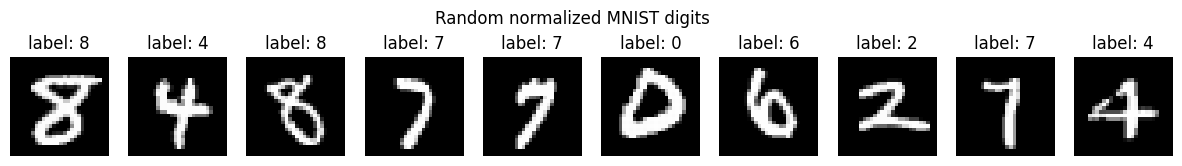

In [4]:
# Visualize 10 random digits (sampled without replacement)
idx = np.random.choice(len(X_norm), size=10, replace=False)
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for ax, i in zip(axes, idx):
    ax.imshow(X_norm[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"label: {y[i]}")
    ax.axis("off")
plt.suptitle("Random normalized MNIST digits")
plt.show()

In [5]:
# 70 / 15 / 15 split (stratified so every split has the same class balance)
X_fit, X_rest, y_fit, y_rest = train_test_split(
    X_norm, y, test_size=0.30, random_state=SEED, stratify=y)
X_tune, X_report, y_tune, y_report = train_test_split(
    X_rest, y_rest, test_size=0.50, random_state=SEED, stratify=y_rest)
print(f"fitting: {len(X_fit)}  tuning: {len(X_tune)}  reporting: {len(X_report)}")

def make_loader(Xa, ya, shuffle):
    ds = TensorDataset(torch.from_numpy(Xa), torch.from_numpy(ya.astype(np.int64)))
    return DataLoader(ds, batch_size=128, shuffle=shuffle)

fitting_loader   = make_loader(X_fit, y_fit, shuffle=True)
tuning_loader    = make_loader(X_tune, y_tune, shuffle=False)
reporting_loader = make_loader(X_report, y_report, shuffle=False)

fitting: 49000  tuning: 10500  reporting: 10500


## 3. Autoencoder

In this section, you will build and train an **autoencoder** to reconstruct the provided data.

Your model will include three layers in both the encoder and decoder:

- **Encoder:** 784 → 128 → 64 → 2. This last layer here is the **bottleneck**.
- **Decoder:** 2 → 64 → 128 → 784  

### 3.1 Implementation (30 points)

Follow the skeleton provided below and fill in the missing parts (`#TODO`). 

Follow these restrictions:

- Each **hidden** layer should include a linear transformation, ReLU activation function, dropout with `p=0.2` and batch normalization steps. Determine the appropriate order for these components based on what we discussed in class. The bottleneck layer is the exception; see next point.
- For the bottleneck, use only a linear transformation, i.e., no activation, batch normalization, or dropout.
- The output layer should have a sigmoid activation function.

In [6]:
import torch.nn as nn

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        # ENCODING PART: 784 -> 128 -> 64 -> 2
        # Hidden block order: Linear -> BatchNorm -> ReLU -> Dropout
        encoder_list = [
            nn.Linear(784, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(p=0.2),
            nn.Linear(128, 64),  nn.BatchNorm1d(64),  nn.ReLU(), nn.Dropout(p=0.2),
            nn.Linear(64, 2),    # bottleneck: linear only
        ]
        self.encoder_list = nn.ModuleList(encoder_list)

        # DECODING PART: 2 -> 64 -> 128 -> 784
        decoder_list = [
            nn.Linear(2, 64),    nn.BatchNorm1d(64),  nn.ReLU(), nn.Dropout(p=0.2),
            nn.Linear(64, 128),  nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(p=0.2),
            nn.Linear(128, 784), nn.Sigmoid(),        # output layer
        ]
        self.decoder_list = nn.ModuleList(decoder_list)

    def encode(self, X):
        for layer in self.encoder_list:
            X = layer(X)
        return X

    def decode(self, Z):
        for layer in self.decoder_list:
            Z = layer(Z)
        return Z

    def forward(self, X):
        output = self.decode(self.encode(X))
        return output

### 3.2 Training (15 points)

Follow the skeleton provided below and fill in the missing parts to train your model (`#TODO`). As you can see, training includes EarlyStopping, which I give you already for your convenience :-). After you have filled these missing parts, uncomment the provided piece of code with the function for training (`train_autoencoder`) your model and execute it.

But, **BEFORE** that, discuss with your mates and provide elaborated answers to the following:

- Why do you think the output layer of the autoencoder above uses a Sigmoid activation?
- Based on this, which cost function is most appropriate for this task? Justify your choice.

**Why a Sigmoid output?** Our targets are pixel intensities that we normalized to $[0, 1]$. The sigmoid $\sigma(z) = 1/(1+e^{-z})$ maps any real number into $(0, 1)$, so every reconstructed pixel is automatically in the same range as the input. The network can never output an impossible value like $-0.3$ or $1.7$, and we don't have to clip anything. Each output can be read as "how bright, or how likely to be ink, is this pixel."

**Which cost function?** We chose **binary cross-entropy (`nn.BCELoss`)**, averaged over pixels:
$$\mathcal{L}(x, \tilde{x}) = -\frac{1}{784}\sum_{j}\big[x_j \log \tilde{x}_j + (1-x_j)\log(1-\tilde{x}_j)\big].$$
- BCE is well defined for any target in $[0, 1]$, not just 0/1 labels. MNIST pixels are mostly near 0 or 1 with soft anti-aliased edges, so treating each pixel as a Bernoulli "ink probability" is a natural model.
- BCE pairs well with the sigmoid. The gradient of BCE with respect to the pre-activation $z$ is just $\sigma(z) - x$, so the sigmoid's derivative cancels. With MSE, the gradient contains an extra factor $\sigma'(z)$ that goes to 0 when the output saturates near 0 or 1, which slows learning exactly on the confidently wrong pixels.
- BCE punishes confident mistakes hard (the loss goes to $\infty$ as $\tilde{x}_j \to 0$ while $x_j = 1$), which pushes the decoder to get the strokes right.

**MSE (`nn.MSELoss`) would also be a reasonable choice** for continuous values in $[0, 1]$. It is easier to interpret (average squared pixel error) and is the loss under which a *linear* autoencoder is equivalent to PCA. To make a fair comparison with PCA possible, we also report reconstruction **MSE** on the reporting set below, whatever loss we trained with.

One caveat when reading the numbers: on soft targets ($0 < x_j < 1$), BCE cannot reach 0 even for a perfect reconstruction. Its minimum is the entropy of the target pixels, so the BCE value is not an "error percentage." We compute that floor below.

Once you have discussed and agreed on the reasoning above, proceed to complete the skeleton (`#TODO`) and train the model.


In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)

model = Autoencoder().to(device)

criterion = nn.BCELoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)
print(model)
print("Device:", device)

Autoencoder(
  (encoder_list): ModuleList(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=64, out_features=2, bias=True)
  )
  (decoder_list): ModuleList(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=128, out_featur

In [8]:
import torch

class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, tuning_loss, model):
        if self.best_loss is None or tuning_loss < self.best_loss - self.min_delta:
            self.best_loss = tuning_loss
            self.counter = 0
            self.best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

    def restore_best_weights(self, model):
        if self.best_model_state is not None:
            model.load_state_dict(self.best_model_state)


def train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=100, patience=5):
    # Initialize the early stopping object
    early_stopping = EarlyStopping(patience=patience)
    history = {"fitting": [], "tuning": []}

    for epoch in range(n_epochs):
        model.train()
        fitting_cost = 0.0

        for X_batch, _ in fitting_loader:
            # --- Implement the standard training steps ---
            
            X_batch = X_batch.to(device)
            outputs = model(X_batch)               # forward pass
            cost = criterion(outputs, X_batch)     # reconstruction cost (target = input)
            cost.backward()                        # compute gradients
            optimizer.step()                       # update parameters
            optimizer.zero_grad()                  # reset gradients
            fitting_cost += cost.item() * X_batch.size(0)

        fitting_cost /= len(fitting_loader.dataset)

        # --- Tuning phase ---
        model.eval()
        tuning_cost = 0.0
        with torch.no_grad():
            for X_batch, _ in tuning_loader:
                X_batch = X_batch.to(device)
                outputs = model(X_batch)
                cost = criterion(outputs, X_batch)
                tuning_cost += cost.item() * X_batch.size(0)

        tuning_cost /= len(tuning_loader.dataset)

        # --- Save metrics ---
        history["fitting"].append(fitting_cost)
        history["tuning"].append(tuning_cost)

        print(f"Epoch [{epoch+1}/{n_epochs}]  Fitting Cost: {fitting_cost:.5f}  Tuning Cost: {tuning_cost:.5f}")

        # --- Early stopping check ---
        early_stopping(tuning_cost, model)
        if early_stopping.early_stop:
            print(f"Stopping early at epoch {epoch+1}")
            early_stopping.restore_best_weights(model)
            return model, history

    return model, history


Once the missing parts have been filled, uncomment the piece of code below and execute it to train your model (it may take a bit to complete the training, which is totally normal).

In [9]:
model, history = train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=50, patience=5)

Epoch [1/50]  Fitting Cost: 0.25957  Tuning Cost: 0.21104


Epoch [2/50]  Fitting Cost: 0.21200  Tuning Cost: 0.20138


Epoch [3/50]  Fitting Cost: 0.20689  Tuning Cost: 0.19780


Epoch [4/50]  Fitting Cost: 0.20452  Tuning Cost: 0.19583


Epoch [5/50]  Fitting Cost: 0.20316  Tuning Cost: 0.19421


Epoch [6/50]  Fitting Cost: 0.20229  Tuning Cost: 0.19295


... (32 outputs left out)

Epoch [39/50]  Fitting Cost: 0.19649  Tuning Cost: 0.18686


Epoch [40/50]  Fitting Cost: 0.19650  Tuning Cost: 0.18667


Epoch [41/50]  Fitting Cost: 0.19630  Tuning Cost: 0.18695


Epoch [42/50]  Fitting Cost: 0.19630  Tuning Cost: 0.18697
Stopping early at epoch 42


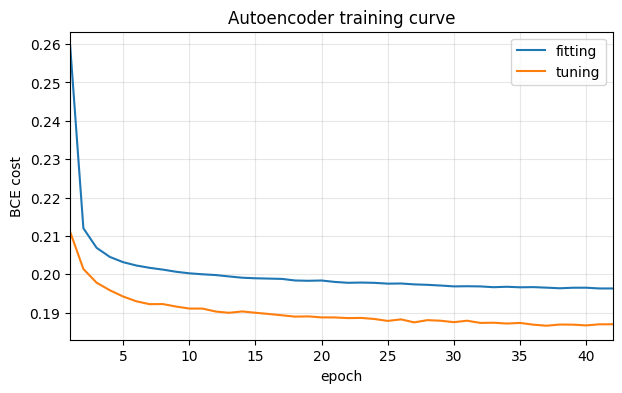

Epochs run: 42 | best tuning BCE: 0.18659


In [10]:
epochs = np.arange(1, len(history["fitting"]) + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, history["fitting"], label="fitting")
plt.plot(epochs, history["tuning"], label="tuning")
plt.xlabel("epoch"); plt.ylabel("BCE cost"); plt.xlim(1, epochs[-1])
plt.title("Autoencoder training curve")
plt.legend(); plt.grid(alpha=0.3); plt.show()
print(f"Epochs run: {len(epochs)} | best tuning BCE: {min(history['tuning']):.5f}")

In [11]:
# Reporting-set evaluation (explicitly in eval mode: BatchNorm uses running stats, dropout off)
model.eval()
X_report_t = torch.from_numpy(X_report).to(device)
with torch.no_grad():
    recon_report = model(X_report_t).cpu().numpy()

eps = 1e-7
bce_report = float(nn.functional.binary_cross_entropy(torch.from_numpy(recon_report), torch.from_numpy(X_report)))
p = np.clip(X_report, eps, 1 - eps)
bce_floor = float(np.mean(-(X_report * np.log(p) + (1 - X_report) * np.log(1 - p))))
mse_ae = float(np.mean((recon_report - X_report) ** 2))

print(f"Fraction of non-binary pixels       : {np.mean((X_report > 0) & (X_report < 1)):.3f}")
print(f"Reporting BCE                        : {bce_report:.4f}")
print(f"BCE floor (perfect reconstruction)   : {bce_floor:.4f}")
print(f"Excess BCE above floor               : {bce_report - bce_floor:.4f}")
print(f"Reporting MSE (autoencoder)          : {mse_ae:.4f}")
print(f"Baseline MSE (predict the mean image): {np.mean((X_report - X_fit.mean(0)) ** 2):.4f}")

Fraction of non-binary pixels       : 0.181
Reporting BCE                        : 0.1865
BCE floor (perfect reconstruction)   : 0.0581
Excess BCE above floor               : 0.1284
Reporting MSE (autoencoder)          : 0.0419
Baseline MSE (predict the mean image): 0.0672


**Reading the training curve.** The tuning cost sits *below* the fitting cost for most of training. That does not mean we're doing better on unseen data than on training data. Two things cause it:
1. dropout is active only in `model.train()`, so the fitting cost is computed on a deliberately crippled network, and
2. the fitting cost is averaged over the epoch while the weights are still improving, whereas the tuning cost is measured at the end of the epoch.

The BCE floor shows that a perfect reconstruction would still score about the floor value printed above, because of the soft edge pixels. Only the **excess** above the floor is actual reconstruction error, and that excess is still substantial: a 2-D code cannot store all the detail of a digit.

### 3.3 Reconstruct (5 points)

Once you have trained the model: 

1. Visualize several reconstructed digits from the reporting set.  
2. Compare them with the corresponding original input digits. Was the reconstruction good? 

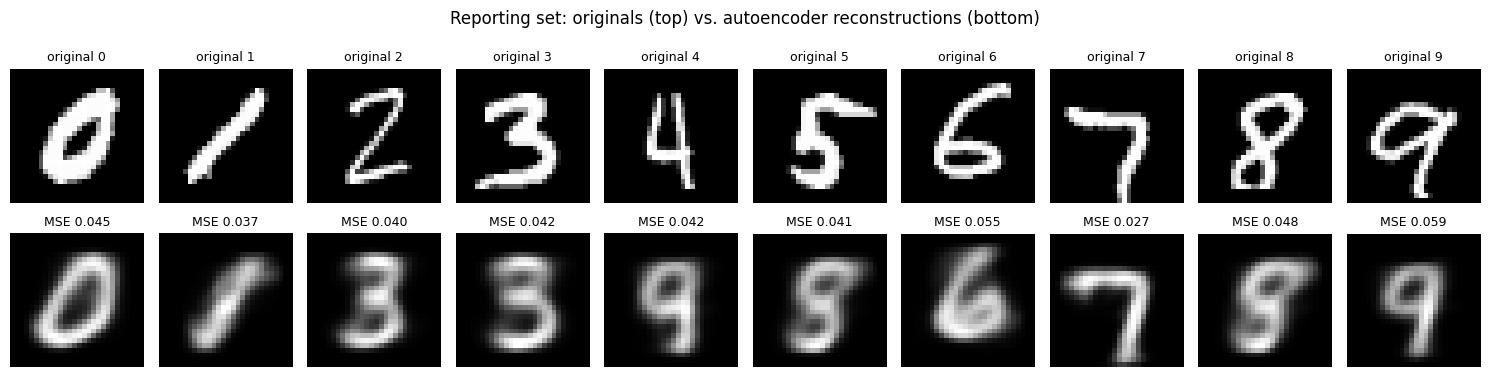

In [12]:
# One reporting-set example per digit class, plus a few extra random ones
rng = np.random.default_rng(SEED)
show_idx = [int(rng.choice(np.where(y_report == d)[0])) for d in range(10)]

fig, axes = plt.subplots(2, 10, figsize=(15, 4))
for col, i in enumerate(show_idx):
    axes[0, col].imshow(X_report[i].reshape(28, 28), cmap="gray")
    axes[0, col].set_title(f"original {y_report[i]}", fontsize=9)
    axes[1, col].imshow(recon_report[i].reshape(28, 28), cmap="gray")
    axes[1, col].set_title(f"MSE {np.mean((recon_report[i]-X_report[i])**2):.3f}", fontsize=9)
for ax in axes.ravel(): ax.axis("off")
plt.suptitle("Reporting set: originals (top) vs. autoencoder reconstructions (bottom)")
plt.tight_layout(); plt.show()

In [13]:
# Per-class reconstruction MSE
per_class_mse = {d: float(np.mean((recon_report[y_report == d] - X_report[y_report == d]) ** 2)) for d in range(10)}
for d, m in per_class_mse.items():
    print(f"digit {d}: MSE = {m:.4f}")

# Does the reconstruction keep the digit's identity? Train a simple classifier on the
# original fitting images and compare its accuracy on original vs. reconstructed reporting images.
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression(max_iter=300).fit(X_fit[:20000], y_fit[:20000])
acc_orig = clf.score(X_report, y_report)
acc_recon = clf.score(recon_report, y_report)
print(f"\nClassifier accuracy on original reporting images     : {acc_orig:.3f}")
print(f"Classifier accuracy on reconstructed reporting images: {acc_recon:.3f}")

digit 0: MSE = 0.0445
digit 1: MSE = 0.0138
digit 2: MSE = 0.0579
digit 3: MSE = 0.0482
digit 4: MSE = 0.0453
digit 5: MSE = 0.0505
digit 6: MSE = 0.0424
digit 7: MSE = 0.0347
digit 8: MSE = 0.0495
digit 9: MSE = 0.0368



Classifier accuracy on original reporting images     : 0.912
Classifier accuracy on reconstructed reporting images: 0.694


/opt/miniconda3/envs/py3114/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


**Was the reconstruction good? Only partly.**
- The reconstructions get the **coarse shape** right: position, size, slant, and the overall outline of the stroke. Digits with a distinctive outline, like **0** and **1**, usually come back recognizably.
- They are clearly **blurry** and lose fine detail: stroke thickness, small loops and gaps, and individual handwriting quirks. With only 2 numbers to describe a whole image, the best the decoder can do for a given code is output something like the *average* of all digits that map near that code. That averaging, rather than the choice of loss, is what makes the output blurry.
- For some classes the reconstruction looks like **a different digit**. In the examples above, the **4** comes back as a **9**, the **2** as something close to a **3**, and the **5** and **8** as similar 8-like blobs. Digits **0, 1, 6, 7, 9** are reconstructed recognizably. The classifier check puts a number on this: a logistic regression that scores **91.2%** on the original reporting images scores only **69.4%** on their reconstructions. Roughly one in four or five reconstructions loses its identity.
- Per-class MSE measures *pixel* error, not identity. Thin digits like 1 have low MSE simply because they contain few ink pixels, so a low MSE does not by itself mean the digit was reconstructed correctly.

Overall, the autoencoder compresses each image to 2 numbers and still keeps the rough shape, which is impressive: its reporting-set MSE is **0.042**, compared with **0.067** for simply predicting the mean image. But a 2-D bottleneck is too small for faithful reconstructions. A wider bottleneck (for example 8–16 dimensions) would give much sharper outputs.

## 4. Visualize the Learned Representations (15 points)

Here you will explore the latent representations learned by your autoencoder.

1. Complete `extract_latent_features` to extract the latent (bottleneck) features and their corresponding labels, given a trained model.  
   Apply this function to the reporting set using the provided code. This should give you the transformed reporting set with the dimensions of the bottleneck (2).
2. Plot the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.


In [14]:
def extract_latent_features(model, dataloader): 
    model.eval()
    latents = []
    labels = []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            
            encoded = model.encode(X_batch.to(device))  # apply only the encoder
            latents.append(encoded.cpu().numpy())
            labels.append(y_batch.numpy())

    # Concatenate all batches
    latents = np.concatenate(latents, axis=0)
    labels = np.concatenate(labels, axis=0)
    return latents, labels

Once the missing parts above have been filled, uncomment the piece of code below and execute it to extract the latent features

In [15]:
latents_autoencoder, labels = extract_latent_features(model, reporting_loader)

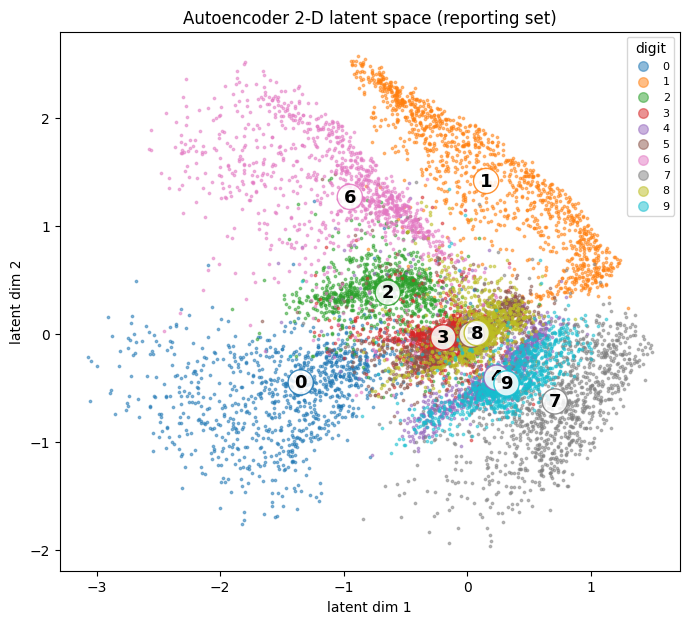

Latent shape: (10500, 2)


In [16]:
def scatter_by_label(ax, Z, labels, title, xlabel, ylabel):
    cmap = plt.get_cmap("tab10")
    for d in range(10):
        m = labels == d
        ax.scatter(Z[m, 0], Z[m, 1], s=3, alpha=0.5, color=cmap(d), label=str(d))
        cx, cy = np.median(Z[m, 0]), np.median(Z[m, 1])
        ax.text(cx, cy, str(d), fontsize=13, weight="bold", ha="center", va="center",
                bbox=dict(boxstyle="circle,pad=0.2", fc="white", ec=cmap(d), alpha=0.85))
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.legend(markerscale=4, title="digit", loc="best", fontsize=8)

fig, ax = plt.subplots(figsize=(8, 7))
scatter_by_label(ax, latents_autoencoder, labels, "Autoencoder 2-D latent space (reporting set)",
                 "latent dim 1", "latent dim 2")
plt.show()
print("Latent shape:", latents_autoencoder.shape)

**What the latent space shows.** Although the autoencoder never saw a single label, the reporting-set codes group strongly by digit.
- **0**, **1**, **6**, and **7** each form their own, mostly separate region, in the left, top-right, top-left, and bottom-right of the plot respectively. **2** also has its own band, just above the center.
- **3**, **5**, and **8** pile up together in the center of the plot.
- **4** and **9** lie almost on top of each other, right next to the 7s.
- This matches what we saw in Section 3.3. When the codes for 4 and 9 (or 3/5/8) overlap, the decoder cannot tell them apart, so a 4 is reconstructed as a 9 and a 5 as an 8-like blob. The overlap in the latent space is the direct cause of the identity errors in the reconstructions.
- The clusters are elongated "arms" radiating from the center rather than round blobs (the 1s, for example, form a long curved arm). Moving along an arm mostly changes style (thickness, slant), while moving toward the center blends the digits.
- The axes themselves have no fixed meaning. They aren't ordered by importance or orthogonal, and a different seed would give a rotated or reflected layout.

## 5. Compare with PCA (10 points)

Here you will compare the latent representations learned by your autoencoder with those obtained using a PCA.

1. Apply a PCA to the reporting set (without using the autoencoder) to reduce the data to the same dimensionality as your bottleneck (2 dimensions). Obviously, first use the rest of the data to learn these two components.
2. Visualize the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.
3. Compare the structure of the two plots (Autoencoder vs. PCA) and briefly discuss the differences (if any) you observe.

In [17]:
from sklearn.decomposition import PCA

# Learn the 2 components on the rest of the data (fitting + tuning), then only TRANSFORM the reporting set
X_pca_fit = np.vstack([X_fit, X_tune])
pca = PCA(n_components=2, random_state=SEED).fit(X_pca_fit)
latents_pca = pca.transform(X_report)

print("Explained variance ratio per component:", np.round(pca.explained_variance_ratio_, 4))
print(f"Total explained variance (2 PCs): {pca.explained_variance_ratio_.sum():.2%}")

# Reconstruction error with 2 PCs vs. the autoencoder (same reporting set)
recon_pca = pca.inverse_transform(latents_pca)
mse_pca = float(np.mean((recon_pca - X_report) ** 2))
print(f"Reporting MSE  PCA (2 dims): {mse_pca:.4f}")
print(f"Reporting MSE  AE  (2 dims): {mse_ae:.4f}")
acc_pca_recon = clf.score(np.clip(recon_pca, 0, 1), y_report)
print(f"Classifier accuracy on PCA reconstructions: {acc_pca_recon:.3f}  (AE: {acc_recon:.3f})")

Explained variance ratio per component: [0.0975 0.0715]
Total explained variance (2 PCs): 16.89%
Reporting MSE  PCA (2 dims): 0.0558
Reporting MSE  AE  (2 dims): 0.0419
Classifier accuracy on PCA reconstructions: 0.367  (AE: 0.694)


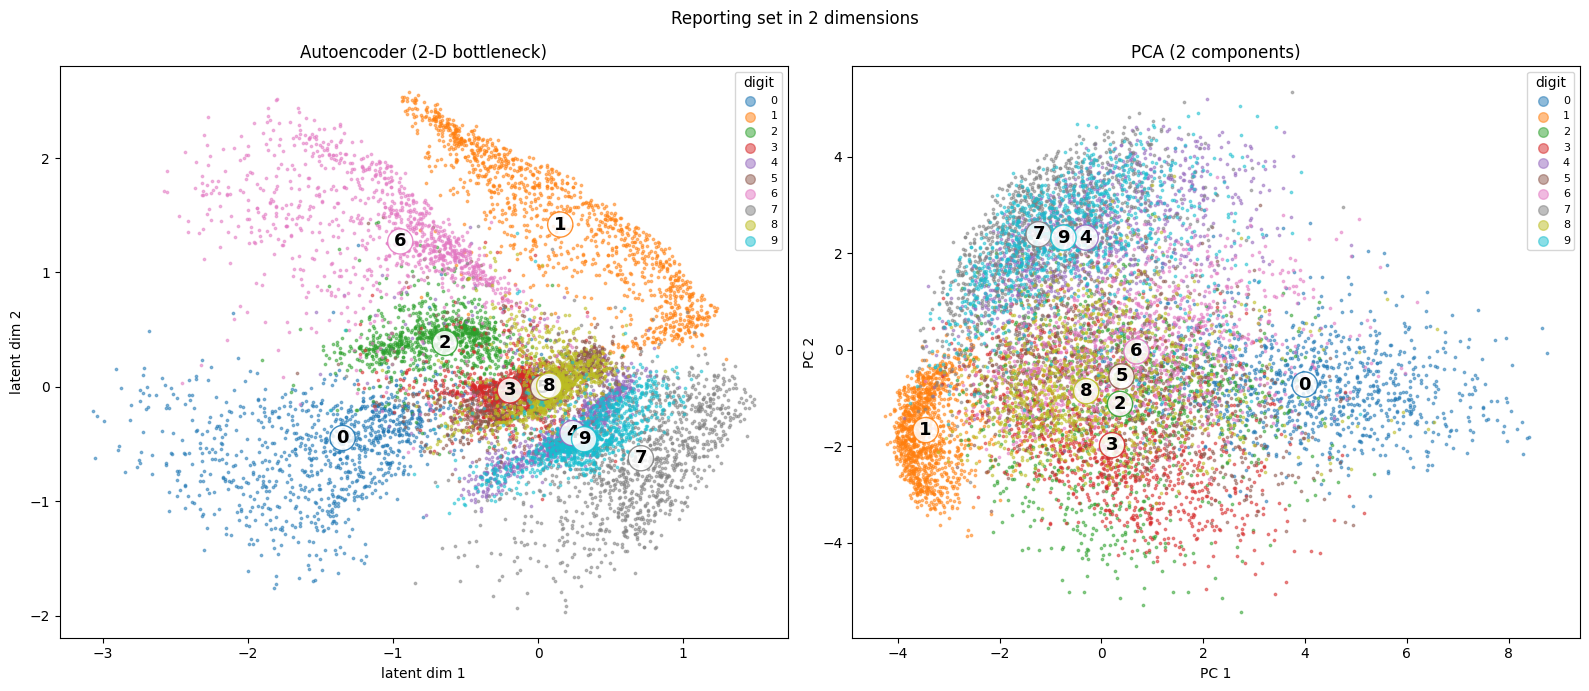

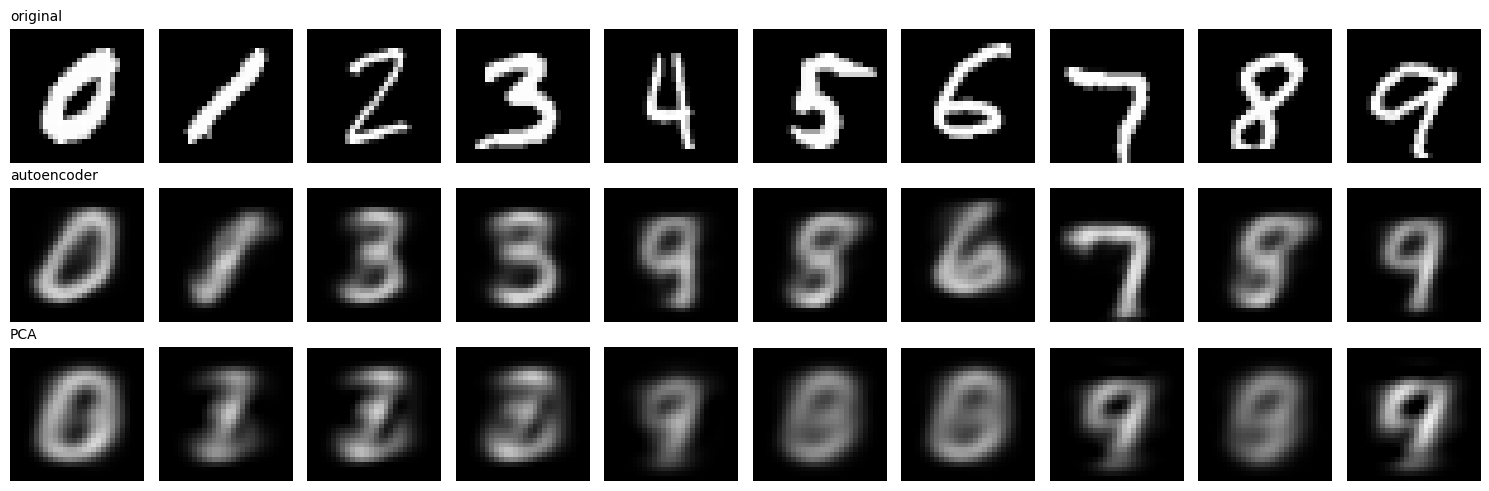

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
scatter_by_label(axes[0], latents_autoencoder, labels, "Autoencoder (2-D bottleneck)", "latent dim 1", "latent dim 2")
scatter_by_label(axes[1], latents_pca, y_report, "PCA (2 components)", "PC 1", "PC 2")
plt.suptitle("Reporting set in 2 dimensions")
plt.tight_layout(); plt.show()

# Reconstructions side by side
fig, axes = plt.subplots(3, 10, figsize=(15, 5))
for col, i in enumerate(show_idx):
    for row, img in enumerate([X_report[i], recon_report[i], recon_pca[i]]):
        axes[row, col].imshow(img.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        axes[row, col].axis("off")
for row, name in enumerate(["original", "autoencoder", "PCA"]):
    axes[row, 0].set_title(name, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

**Comparison: autoencoder vs. PCA.**
- **Cluster structure.** In the PCA plot most classes pile up in one large, overlapping cloud. **1** and **0** sit at opposite ends of PC 1 (roughly "thin vertical stroke" vs. "big round ring"), and **4/7/9** form one shared blob at the top along PC 2. Digits **2, 3, 5, 6, 8** are smeared together in the middle with their centers almost touching. The autoencoder's 2-D space is much more organized: 0, 1, 2, 6, and 7 get their own regions, and only the visually similar groups (4/9, 3/5/8) still overlap.
- **Why.** PCA can only rotate and project the data *linearly* onto the two directions of largest variance, and those two directions explain only **16.9%** of the total pixel variance (9.8% + 7.2%). The autoencoder's non-linear encoder can bend and stretch the space so that images that look alike end up close together, even when that relationship isn't linear in pixel space.
- **Reconstruction.** For the same 2 dimensions, the autoencoder's reporting-set reconstruction MSE is **0.042**, compared with **0.056** for PCA (and 0.067 for the mean image). Its reconstructions also keep the digit's identity far more often: the classifier gets **69.4%** right on AE reconstructions vs. **36.7%** on PCA reconstructions. PCA's reconstructions are ghostly blends of the mean digit plus two "eigendigits."
- **Shape and interpretability.** PCA axes are orthogonal, ordered (PC 1 carries the most variance), and reproducible. The autoencoder's axes are arbitrary, its clusters form curved arms, and its layout depends on the random seed. PCA is also deterministic, has no hyperparameters, and fits in seconds.
- **Caveats.** These results come from a single training run (one seed). Part of the gap may come from differences other than non-linearity, such as depth, BCE loss, and BatchNorm. A linear autoencoder trained with MSE should end up close to PCA.

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE — **write 3–5 sentences about your own group's experience** (one challenge or inefficiency, how it affected the work, and one concrete action for next lab).